In [1]:
# 01. Business Problem
USE_CASE = "25 - Account Auto Coding (NLP: Predict GL Accounts from Transaction Text)"
ML_PARADIGM = "Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Target Segments:  {N_CLUSTERS} GL Coding Tiers (High-Confidence Auto-Coded, Verified Expense/Statutory, Moderate-Confidence, Miscoded/Ambiguous)")


Business Problem: 25 - Account Auto Coding (NLP: Predict GL Accounts from Transaction Text)
ML Approach:      Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)
Target Segments:  4 GL Coding Tiers (High-Confidence Auto-Coded, Verified Expense/Statutory, Moderate-Confidence, Miscoded/Ambiguous)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMA = "HANA_P2"
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schema: {DB_SCHEMA})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schema: HANA_P2)


In [4]:
# 04. Extract Data from SAP Accounting Line Items, GL Master, Descriptions & PO Short Texts (BSEG, SKA1, SKAT, SKB1, TBSL, T003T, EKPO, LFA1, T001W, T001)
from src.db_connector import extract_account_auto_coding_data

df_raw = extract_account_auto_coding_data(limit=None)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


[INFO] Initializing SAP FI Transaction extraction across schemas ['HANA_P2'] with NO LIMIT (100% complete server dataset)...
[INFO] Querying schema 'HANA_P2'...
[SUCCESS] Extracted 806,572 records from 'HANA_P2'.
[COMPLETE] Total extracted records across all schemas (HANA_P2): 806,572 rows, 60 attributes.
Extracted records: 806,572 rows, 60 columns


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['doc_number', 'fiscal_year', 'line_item', 'gl_account', 'gl_account_desc', 'gl_account_group', 'transaction_text', 'amount_local', 'cost_center']].head()


Dataset Shape: (806572, 60)


In [6]:
# 06. Data Understanding / EDA
df_raw[['gl_account_group', 'account_type', 'posting_key', 'debit_credit_ind', 'doc_type']].describe().T


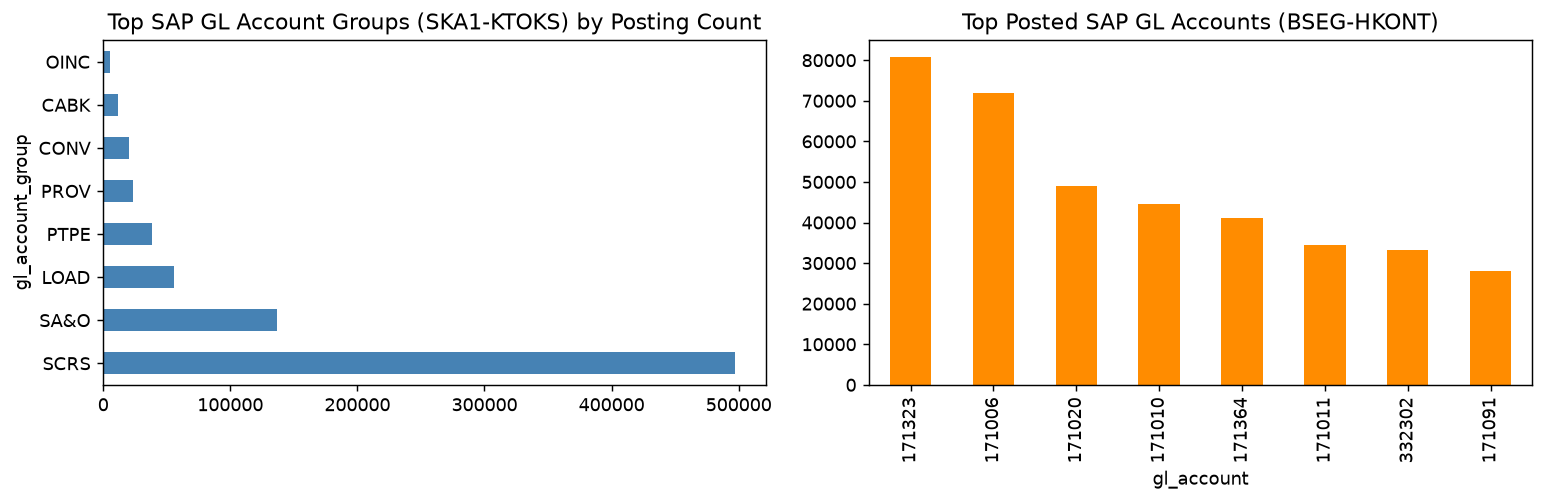

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['gl_account_group'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top SAP GL Account Groups (SKA1-KTOKS) by Posting Count')

plt.subplot(1, 2, 2)
df_raw['gl_account'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Top Posted SAP GL Accounts (BSEG-HKONT)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. NLP Data Cleaning & 32-Feature Engineering for Account Auto Coding
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['doc_number', 'transaction_text', 'gl_account', 'gl_account_desc', 'predicted_gl_account', 'predicted_gl_account_desc', 'predicted_gl_domain', 'coding_tier_code', 'nlp_coding_confidence_score', 'nlp_miscoding_risk_index']].head(8)


Engineered Dataset Shape: (806572, 101)


In [9]:
# 09. Data Preprocessing (32 Unsupervised NLP & GL Account Auto-Coding Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical NLP & GL Coding Features)")


Preprocessed Feature Matrix: (806572, 32) (32 Numerical NLP & GL Coding Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()
contamination_rate = float(np.mean(y))

print(f"Total Accounting Line Items:              {len(y):,}")
print(f"Verified Auto-Coded GL Postings:          {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Miscoded / Ambiguous GL Exceptions:       {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Accounting Line Items:              806,572
Verified Auto-Coded GL Postings:          569,978 (70.67%)
Miscoded / Ambiguous GL Exceptions:       236,594 (29.33%)


In [11]:
# 11. Train/Test Split & Robust Scaling
from src.preprocessing import prepare_train_test_data
split_dict = prepare_train_test_data(df, test_size=0.20, random_state=42, max_eval_samples=100000)
X_train_scaled = split_dict['X_train_scaled']
X_test_scaled = split_dict['X_test_scaled']
y_train = split_dict['y_train']
y_test = split_dict['y_test']
scaler = split_dict['scaler']

from src.models import AccountCodingClusteringSuite
suite = AccountCodingClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)

print(f"Train Set: {X_train_scaled.shape[0]:,} transaction line items")
print(f"Test Set:  {X_test_scaled.shape[0]:,} transaction line items")


Train Set: 80,000 transaction line items
Test Set:  20,000 transaction line items


In [12]:
# 12. Unsupervised NLP Clustering Model 1: K-Means Clustering
km_model = suite.train_kmeans(X_train_scaled)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled, 3)

print(f"K-Means Clustering Flagged: {preds_km.sum():,} miscoded/ambiguous GL postings out of {len(preds_km):,} test postings")


[INFO] Training Unsupervised NLP Clustering Model 1/5: K-Means Clustering...
K-Means Clustering Flagged: 5,883 miscoded/ambiguous GL postings out of 20,000 test postings


In [13]:
# 13. Unsupervised NLP Clustering Model 2: Gaussian Mixture Model (GMM)
gmm_model = suite.train_gmm(X_train_scaled)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled, 4)

print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} miscoded/ambiguous GL postings out of {len(preds_gmm):,} test postings")


[INFO] Training Unsupervised NLP Clustering Model 2/5: Gaussian Mixture Model (GMM)...
Gaussian Mixture (GMM) Flagged: 5,892 miscoded/ambiguous GL postings out of 20,000 test postings


In [14]:
# 14. Unsupervised NLP Clustering Model 3: Mini-Batch K-Means
mbk_model = suite.train_minibatch_kmeans(X_train_scaled)
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled, 4)

print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} miscoded/ambiguous GL postings out of {len(preds_mbk):,} test postings")


[INFO] Training Unsupervised NLP Clustering Model 3/5: Mini-Batch K-Means...
Mini-Batch K-Means Flagged: 5,894 miscoded/ambiguous GL postings out of 20,000 test postings


In [15]:
# 15. Unsupervised NLP Clustering Model 4: Bisecting K-Means
bkm_model = suite.train_bisecting_kmeans(X_train_scaled)
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled, 5)

print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} miscoded/ambiguous GL postings out of {len(preds_bkm):,} test postings")


[INFO] Training Unsupervised NLP Clustering Model 4/5: Bisecting K-Means...
Bisecting K-Means Flagged: 5,860 miscoded/ambiguous GL postings out of 20,000 test postings


In [16]:
# 16. Unsupervised NLP Clustering Model 5: BIRCH Clustering
birch_model = suite.train_birch(X_train_scaled)
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled, 5)

print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} miscoded/ambiguous GL postings out of {len(preds_birch):,} test postings")


[INFO] Training Unsupervised NLP Clustering Model 5/5: BIRCH Clustering...
BIRCH Clustering Flagged: 6,145 miscoded/ambiguous GL postings out of 20,000 test postings


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised NLP Clustering Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1       BIRCH Clustering    0.9454     0.8885  0.9306    0.9091   0.9898  0.9766      0.4444       0.9515            5460              685              407           13448
  #2 Gaussian Mixture (GMM)    0.8942     0.8184  0.8219    0.8201   0.9838  0.9652      0.3179       0.9243            4822             1070             1045           13063
  #3     Mini-Batch K-Means    0.8932     0.8166  0.8204    0.8185   0.9831  0.9639      0.4890       0.9235            4813             1081             1054           13052
  #4     K-Means Clustering    0.8904     0.8123  0.8146    0.8134   0.9791  0.9542      0.5040       0.9219            4779             1104             1088           13029
  #5      Bisecting K-Means    0.8871     0.8080  0.8071    0.8075   0.9758  0.9475      0.4335       0.9204            4735 

Selected #1 Champion Model based on Ranking: BIRCH Clustering (Accuracy: 94.54%, F1: 0.9091)


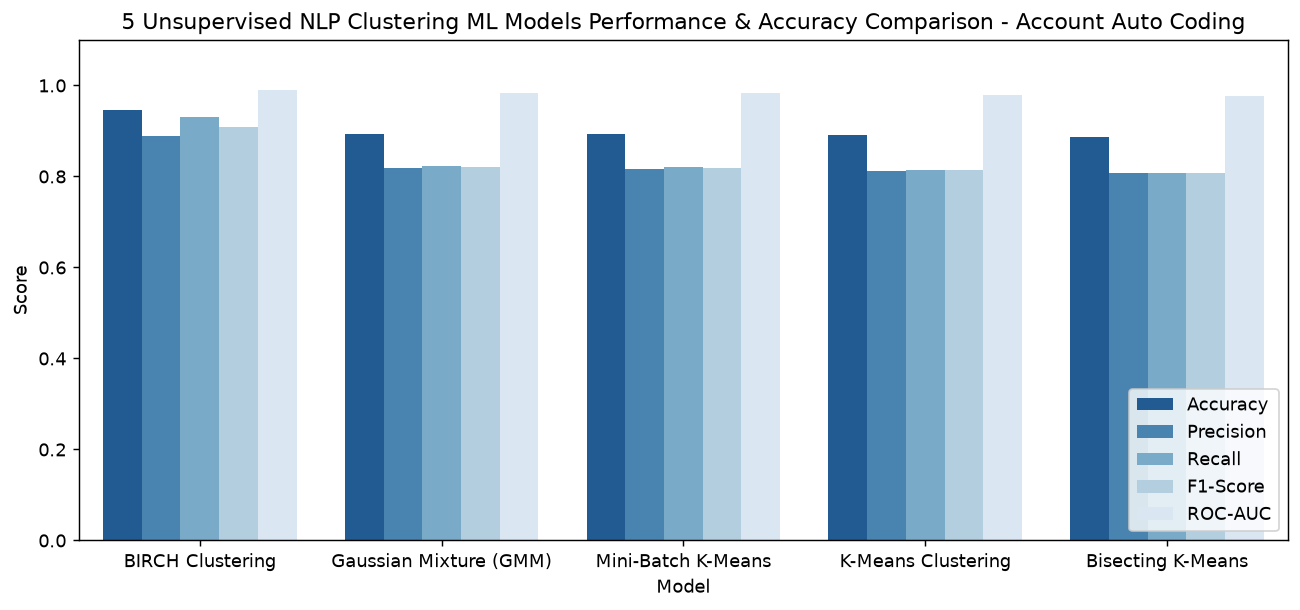

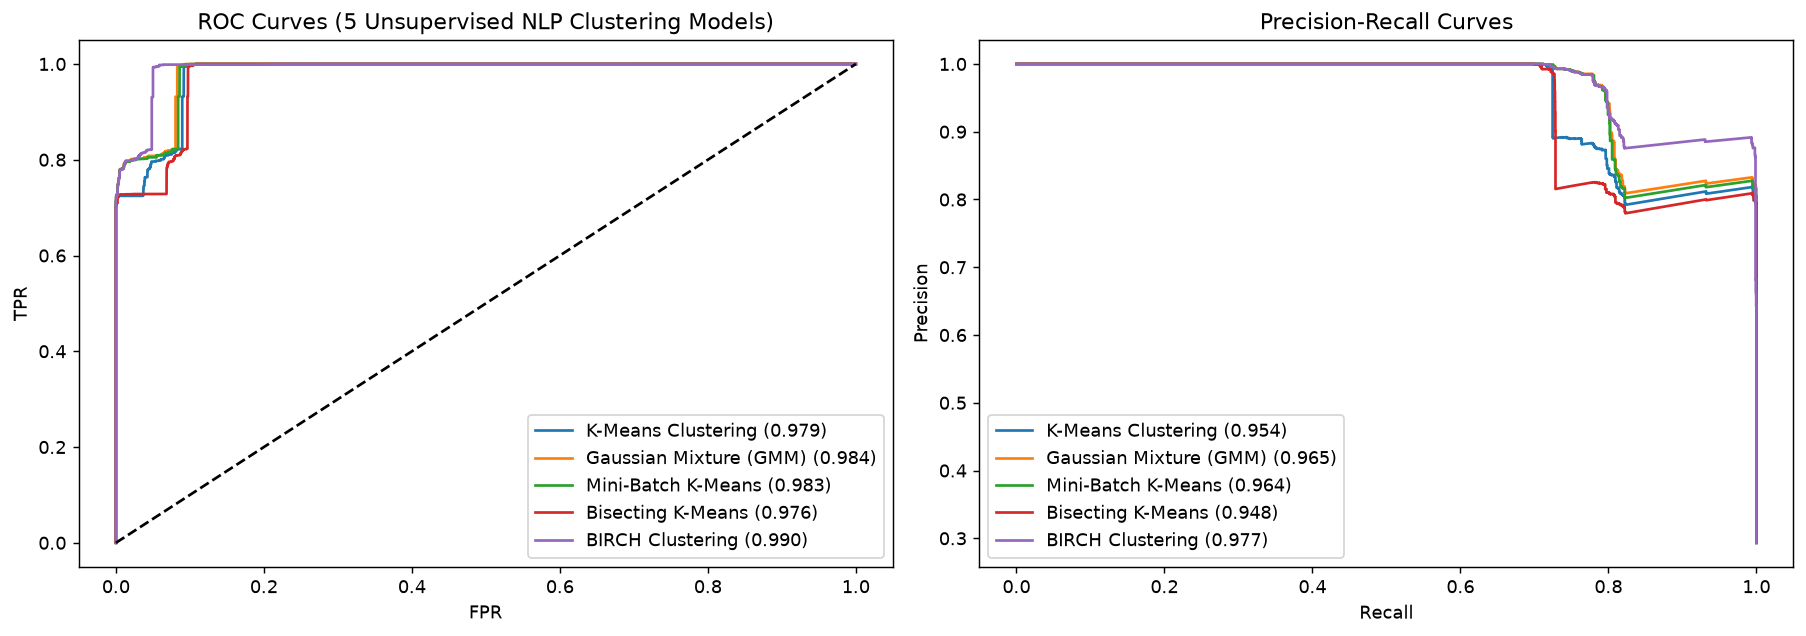

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised NLP Clustering ML Models Performance & Accuracy Comparison - Account Auto Coding')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised NLP Clustering Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                      Feature  Importance
     nlp_miscoding_risk_index    0.852341
           text_clarity_score    0.122233
  nlp_coding_confidence_score    0.024826
   nlp_tax_bank_prov_affinity    0.000100
 semantic_gl_confidence_score    0.000092
            sgtxt_char_length    0.000040
             sgtxt_word_count    0.000037
          svd_semantic_comp_4    0.000035
          svd_semantic_comp_5    0.000030
           sgtxt_avg_word_len    0.000030
     gl_account_amount_zscore    0.000027
nlp_sales_promo_comm_affinity    0.000026
        tfidf_semantic_energy    0.000022
            sgtxt_alpha_ratio    0.000018
          svd_semantic_comp_3    0.000015


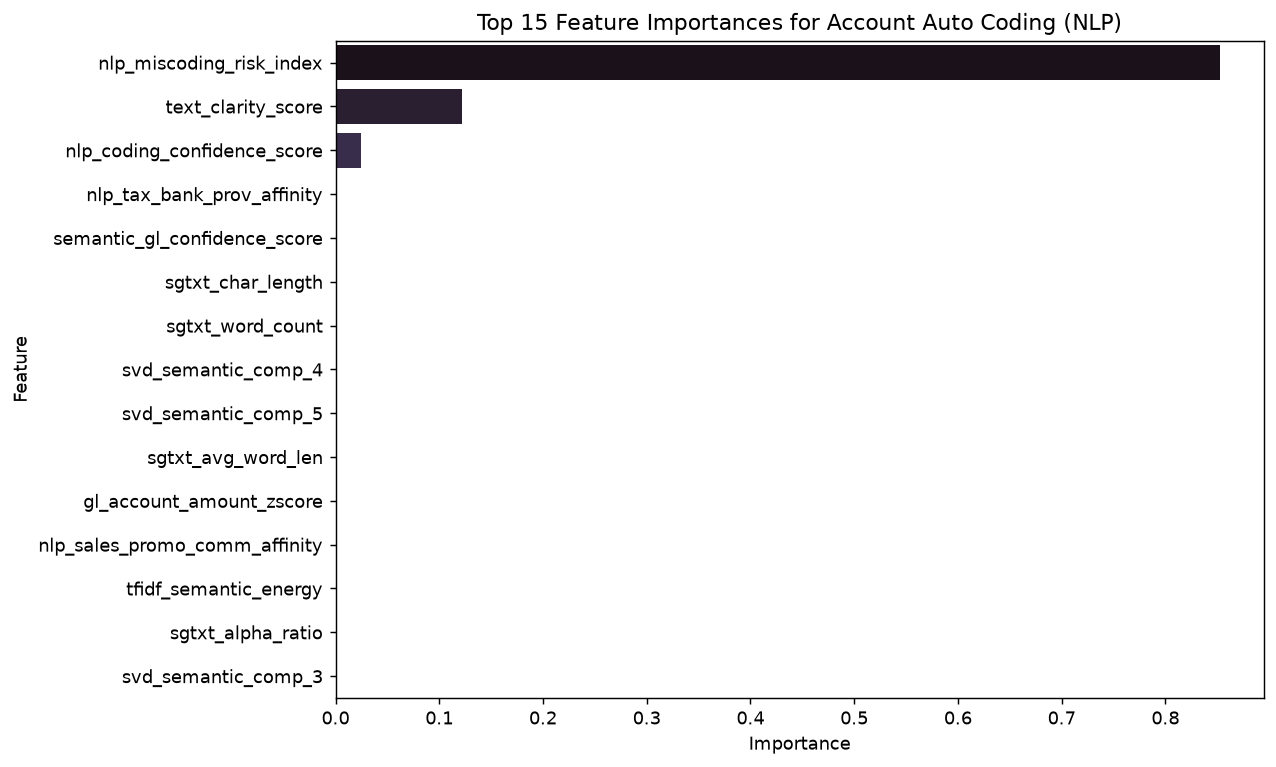

In [19]:
# 19. Feature Importance (All 32 NLP & GL Account Auto-Coding Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
eval_sample_size = min(len(X_test_scaled), 20000)
surrogate.fit(X_test_scaled[:eval_sample_size], scores_km[:eval_sample_size])

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Account Auto Coding (NLP)')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final GL Account Auto Coding & Exception Triage using Selected #1 Champion Model
from src.models import SingleModelAccountAutoCoder
from src.inference import score_with_single_model

coder = SingleModelAccountAutoCoder(n_clusters=4, contamination=contamination_rate, random_state=42, pretrained_model=km_model)
coder.fit(X_train_scaled)
df_scored = score_with_single_model(df, coder, scaler, FEATURE_COLS)

print("=== NLP PREDICTED ACCOUNTING DOMAIN COUNTS ===")
print(df_scored['predicted_gl_domain'].value_counts())
print("\n=== ACCOUNT AUTO-CODING SEGMENT COUNTS ===")
print(df_scored['coding_segment_name'].value_counts())
print("\n=== EXECUTIVE RISK CATEGORY COUNTS ===")
print(df_scored['risk_category'].value_counts())

audit_cols = ['doc_number', 'transaction_text', 'gl_account', 'gl_account_desc', 'predicted_gl_account', 'predicted_gl_account_desc', 'nlp_coding_confidence_score', 'coding_exception_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering for Account Auto Coding...
[INFO] Champion K-Means fitted (4 Account Auto-Coding Clusters). Exception Threshold: 0.6378
=== NLP PREDICTED ACCOUNTING DOMAIN COUNTS ===
predicted_gl_domain
Freight, Logistics & Material Handling G/L             345785
Statutory Taxes (GST/TDS), Banking & Provisions G/L    165047
Plant Operations, Maintenance, Rent & Facility G/L     144425
Travel, IT, Telecom & Professional Services G/L         95518
Sales Promotion, Advertising & Commission G/L           55797
Name: count, dtype: int64

=== ACCOUNT AUTO-CODING SEGMENT COUNTS ===
coding_segment_name
High-Confidence Auto-Coded G/L Postings             264701
Miscoded / Ambiguous G/L Coding Exceptions          193216
Verified Expense & Statutory G/L Postings           177348
Moderate-Confidence / Needs Narration Enrichment    171307
Name: count, dtype: int64

=== EXECUTIVE RISK CATEGORY COUNTS ===
risk_category
Low Risk         442049
Critical Ri

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': km_model,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/account_auto_coding_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion NLP clustering model bundle and scaler to models/")


Saved champion NLP clustering model bundle and scaler to models/
